# Л2 — Сегментація й пошук закономірностей
Спільні правила для всіх методів:

- методам на відстанях (k-середні, Вард, Кохонен) потрібен однаковий масштаб ознак, інакше ознака з великими числами переважить решту;
- кількість кластерів обирають і за метриками, і за тим, чи можна кластер пояснити;
- результат одного методу варто перевірити іншим;
- зв'язок у даних ще не означає причину: його може створювати третій чинник, а в частині даних він може бути протилежним.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця пасток — у `README.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from minisom import MiniSom
from mlxtend.frequent_patterns import apriori, association_rules

## 1. Завантаження даних

Дані цієї роботи вже чисті, тож досить переконатися, що файли прочиталися правильно, і подивитися, що всередині. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

In [8]:
customers = pd.read_parquet("customers.parquet")
events = pd.read_csv("events.csv", parse_dates=["event_ts"])

print(customers.head())
print(customers.tail())

print(customers.shape)
print(customers.dtypes)

print(events.head())
print(events.tail())

print(events.shape)
print(events.dtypes)

  abonent_id  avg_daily_kwh  night_share  seasonality  weekend_ratio  \
0    AB10001         23.542       0.1202       0.7176         0.4405   
1    AB10002         14.250       0.3058       0.9310         1.0192   
2    AB10003         14.244       0.3020       2.1908         0.9990   
3    AB10004         48.079       0.1675       1.0462         0.8134   
4    AB10005         25.378       0.2208       1.8299         1.1140   

   stability  annual_charge_uah  avg_price_uah_kwh  voltage_dev_mean  \
0     0.7524           58861.36              6.850             4.573   
1     0.7116           19032.84              3.659             5.409   
2     0.6219           19069.13              3.668             4.767   
3     0.7822          120210.65              6.850             3.487   
4     0.6603           40016.16              4.320             3.237   

   loss_index_mean     tariff meter_type district  connection_year  churned  
0            5.910   business   IND_1985     west       

## 2. Ознаки для сегментації

Кластеризація спирається на просторову близькість: кожен абонент — точка в просторі ознак, і схожі абоненти лежать поруч. Відстань рахується по всіх ознаках разом, тож ознака з великими числами переважить решту. Обсяг споживання в різних абонентів різниться в сотні разів, тому його спершу логарифмують, а потім усі ознаки стандартизують: середнє 0, стандартне відхилення 1. Грошей і договору серед ознак немає: сегмент описує, як абонент споживає.

Візьміть із `customers` колонки `features`, замініть `avg_daily_kwh` її натуральним логарифмом і стандартизуйте всі колонки. Результат назвіть `X`. Самі `customers` не змінюйте: у кроках 3 і 7 потрібні вихідні значення. Можуть допомогти `np.log` і `StandardScaler().fit_transform`.

In [9]:
features = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability"]

X_df = customers[features].copy()

X_df["avg_daily_kwh"] = np.log(X_df["avg_daily_kwh"])

scaler = StandardScaler()
X = scaler.fit_transform(X_df)

print("Розмір X:", X.shape)
print("\nСередні значення стандартизованих ознак:")
print(X.mean(axis=0))

print("\nСтандартні відхилення:")
print(X.std(axis=0))

print("\nПерші 5 рядків X:")
print(X[:5])

Розмір X: (2000, 5)

Середні значення стандартизованих ознак:
[-4.86721774e-16  1.52766688e-16  2.41584530e-16 -1.69642078e-16
  2.39719355e-15]

Стандартні відхилення:
[1. 1. 1. 1. 1.]

Перші 5 рядків X:
[[ 0.3466414  -1.1069633  -2.03097657 -2.66287403  0.9457565 ]
 [-0.32315265  0.37198657 -1.43360911  0.3335941   0.10490361]
 [-0.32371453  0.34170635  2.09293035  0.22899991 -1.74373619]
 [ 1.29932065 -0.7300542  -1.11113146 -0.73202391  1.55990885]
 [ 0.4468333  -0.30533422  1.08266833  0.82446187 -0.95234524]]


## 3. Головні компоненти (PCA)

PCA повертає осі так, щоб перша головна компонента (principal component) йшла вздовж найбільшого розкиду даних, друга — вздовж найбільшого з решти, і так далі. Кожна компонента — лінійна комбінація вихідних показників. Найчастіше PCA використовують для зменшення розмірності: стиснути багато пов'язаних показників до кількох компонент перед моделлю чи для графіка. Але за нею можна й побачити, які показники змінюються разом, як у факторному аналізі. Тут саме це: погляд на 9 числових показників абонентів (усі числові колонки, крім `connection_year` і `churned`). На сегменти він не впливає.

Як читати результат:

- **eigenvalue** (власне значення) — скільки розкиду пояснює компонента в «одиницях одного показника»: сума eigenvalues ≈ кількість показників. Критерій Кайзера лишає компоненти з eigenvalue більше 1: кожна з них пояснює більше, ніж один показник;
- **loadings** (факторні навантаження) — кореляція показника з компонентою, від −1 до 1. Показники з великим за модулем loading (приблизно від 0.5) і однаковим знаком змінюються разом, з протилежним — у різні боки. Знак самої компоненти умовний: якщо перевернути всі знаки, зміст той самий;
- компоненту називають за її сильними показниками.

Приклад на інших даних — 5 показників 1000 людей. Eigenvalues перших двох компонент — 2.55 і 1.83, третьої — 0.25, тож за Кайзером лишаються дві, і разом вони пояснюють 88% розкиду.

| Показник | PC1 | PC2 |
|---|---|---|
| зріст | 0.92 | −0.12 |
| вага | 0.92 | 0.00 |
| розмір взуття | 0.92 | −0.10 |
| кроків за день | −0.11 | −0.95 |
| час бігу на 1 км | 0.10 | 0.95 |

У PC1 великі й однакові за знаком loadings мають зріст, вага й розмір взуття, решта біля нуля — це «розмір тіла». У PC2 сильні лише кроки й час бігу, і знаки в них протилежні: хто більше ходить, той швидше біжить. Це «активність», а великі значення PC2 тут означають малоактивних людей, бо знак компоненти умовний.

Збережений розкид — ще не збережена користь: для прогнозу може знадобитися саме компонента з малим eigenvalue, і перевірити це можна лише моделлю з цільовою колонкою.

1. Стандартизуйте 9 колонок без логарифма й застосуйте `PCA()`. `X` із кроку 2 не перезаписуйте, він потрібен далі.
2. Виведіть eigenvalues (`explained_variance_`), explained variance ratio кожної компоненти (`explained_variance_ratio_`) і накопичену частку.
3. Виведіть кількість компонент з eigenvalue більше 1.
4. Виведіть таблицю loadings перших двох компонент.
5. Назвіть першу компоненту за її сильними показниками одним реченням — це відповідь для питання 2 звіту.

In [10]:
numeric = customers.select_dtypes(include="number").columns.drop(
    ["connection_year", "churned"]
)

scaler_pca = StandardScaler()
X_pca = scaler_pca.fit_transform(customers[numeric])

pca = PCA()
pca.fit(X_pca)

# Власні значення та частки поясненої дисперсії
eigenvalues = pca.explained_variance_
variance_ratio = pca.explained_variance_ratio_
cumulative_ratio = np.cumsum(variance_ratio)

pca_results = pd.DataFrame({
    "eigenvalue": eigenvalues,
    "explained_variance_ratio": variance_ratio,
    "cumulative_ratio": cumulative_ratio
}, index=[f"PC{i + 1}" for i in range(len(eigenvalues))])

print("Результати PCA:")
print(pca_results.round(4))

print("\nКількість компонент з eigenvalue > 1:", int(np.sum(eigenvalues > 1)))

loadings = pd.DataFrame(
    pca.components_[:2].T * np.sqrt(eigenvalues[:2]),
    index=numeric,
    columns=["PC1", "PC2"]
)

print("\nНавантаження PC1 і PC2:")
print(loadings.round(3))

print("\nПоказники, що найбільше впливають на PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False))

Результати PCA:
     eigenvalue  explained_variance_ratio  cumulative_ratio
PC1      3.6818                    0.4089            0.4089
PC2      1.2419                    0.1379            0.5468
PC3      1.0021                    0.1113            0.6581
PC4      0.9990                    0.1109            0.7690
PC5      0.8460                    0.0940            0.8630
PC6      0.5890                    0.0654            0.9284
PC7      0.3473                    0.0386            0.9670
PC8      0.2736                    0.0304            0.9973
PC9      0.0239                    0.0027            1.0000

Кількість компонент з eigenvalue > 1: 3

Навантаження PC1 і PC2:
                     PC1    PC2
avg_daily_kwh     -0.737  0.594
night_share        0.623  0.189
seasonality        0.704  0.558
weekend_ratio      0.846  0.170
stability         -0.698 -0.423
annual_charge_uah -0.805  0.563
avg_price_uah_kwh -0.634  0.084
voltage_dev_mean  -0.036  0.087
loss_index_mean    0.037 -0.03

## 4. Кількість кластерів

k-середні ділять абонентів на k кластерів. Центр кластера (центроїд) — середнє всіх його точок, тобто усереднений представник: за ним описують увесь кластер. Алгоритм відносить кожного абонента до найближчого центру й перераховує центри, доки абоненти не перестануть переходити між кластерами. Коли кластер вдається описати як тип абонентів, його називають сегментом.

Інерція — сума квадратів відстаней від абонентів до центрів їхніх кластерів. Вона спадає з кожним новим k, тож шукають «лікоть»: місце, де спад сповільнюється. Силует, від −1 до 1, показує, наскільки абонент ближчий до свого кластера, ніж до сусіднього. Він часто найбільший при малих k, бо грубий поділ чіткіший за детальний. Але два кластери нічого не кажуть про типи споживачів, тому k обирають від 3 до 6.

Для k від 2 до 8 побудуйте k-середні на `X`, виведіть таблицю «k, інерція (`inertia_`), силует (`silhouette_score`)» і два графіки: інерція від k і силует від k.

Порівняння кількості кластерів:
 k   inertia  silhouette
 2 5437.6025      0.4584
 3 4250.9543      0.3065
 4 3458.9226      0.3266
 5 3130.1036      0.2869
 6 2871.8144      0.2826
 7 2662.5506      0.2266
 8 2512.1032      0.2256


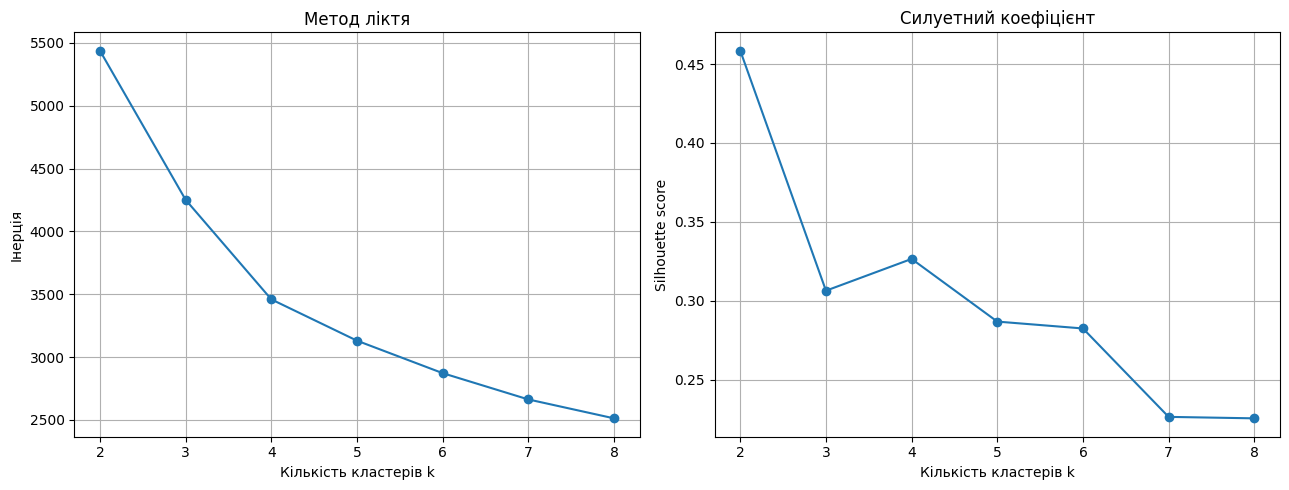

In [11]:
results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    )

    model.fit(X)

    silhouette = silhouette_score(X, model.labels_)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette
    })

results_df = pd.DataFrame(results)

print("Порівняння кількості кластерів:")
print(results_df.round(4).to_string(index=False))

# Графіки
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)
axes[0].set_title("Метод ліктя")
axes[0].set_xlabel("Кількість кластерів k")
axes[0].set_ylabel("Інерція")
axes[0].grid(True)

axes[1].plot(
    results_df["k"],
    results_df["silhouette"],
    marker="o"
)
axes[1].set_title("Силуетний коефіцієнт")
axes[1].set_xlabel("Кількість кластерів k")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 5. Ієрархічна кластеризація

Метод Варда починає з окремих абонентів і щоразу об'єднує два кластери, від злиття яких сума квадратів відстаней усередині кластерів росте найменше. Дендрограма показує всю історію об'єднань: довгі вертикальні лінії вгорі означають, що злито дуже різні кластери, і різати варто саме там.

| | k-середні | Метод Варда |
|---|---|---|
| кількість кластерів | задають наперед | не потрібна: дендрограма показує поділ на будь-яке k |
| що дає | центри кластерів; нового абонента відносять до найближчого центру | ієрархію: видно, які кластери є частинами більших |
| слабке місце | може застрягти в невдалому поділі, тому запускають кілька разів (`n_init`) | невдале раннє об'єднання не виправляється |
| великі дані | швидкий і на мільйонах рядків | рахує відстані між усіма парами, тому повільний |

Тут Вард допомагає обрати k і перевірити, чи поділ стійкий, а сегменти для `segments.csv` беруть із k-середніх: у них є центри, за якими описують сегменти й відносять нових абонентів.

1. Побудуйте `Z = linkage(X, "ward")` і дендрограму верхніх 30 об'єднань: `dendrogram(Z, truncate_mode="lastp", p=30)`.
2. Для k від 3 до 6 виведіть довжину розрізу на k кластерів. `Z[:, 2]` — висоти об'єднань, і розріз на k кластерів лежить між k-м і (k−1)-м об'єднанням з кінця.
3. Дендрограма підказує k із найбільшою довжиною розрізу: такий розріз перетинає найдовші вертикальні лінії.

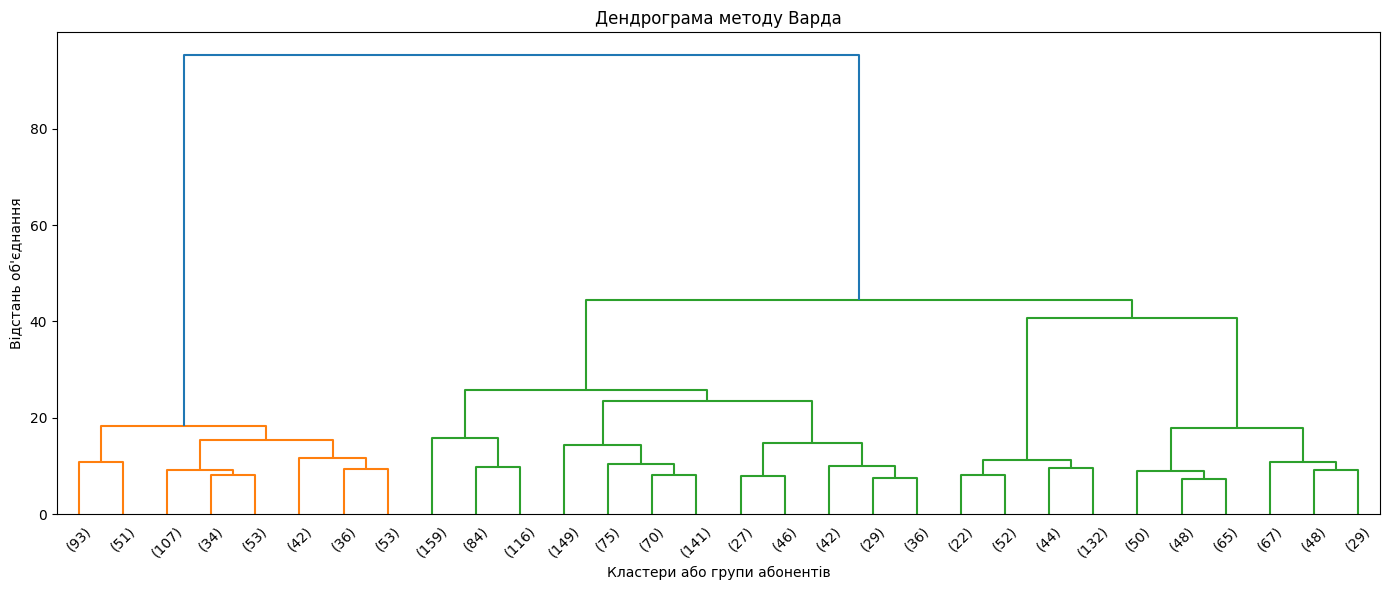

Довжини розрізів:
 k  cut_length
 3      3.6293
 4     14.9949
 5      2.3477
 6      5.0367


In [6]:
# Ієрархічна кластеризація
Z = linkage(X, method="ward")

# Дендрограма останніх 30 об'єднань
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30
)

plt.title("Дендрограма методу Варда")
plt.xlabel("Кластери або групи абонентів")
plt.ylabel("Відстань об'єднання")
plt.tight_layout()
plt.show()

# Довжини розрізів для k від 3 до 6
cut_results = []

for k in range(3, 7):
    cut = Z[-(k - 1), 2] - Z[-k, 2]

    cut_results.append({
        "k": k,
        "cut_length": cut
    })

cut_df = pd.DataFrame(cut_results)

print("Довжини розрізів:")
print(cut_df.round(4).to_string(index=False))

## 6. Порівняння двох поділів

Методи будують кластери по-різному (крок 5), тож поділи можуть різнитися. Якщо вони схожі, кластери відображають структуру самих даних, а не особливість одного методу.

Як порівняти два поділи:

- **таблиця спряженості** (contingency table, `pd.crosstab`): рядок — кластер k-середніх, стовпець — кластер Варда, у клітинці — скільки абонентів потрапили в обидва. Номери в двох методах не пов'язані: кластер 0 k-середніх може відповідати кластеру 3 Варда. Тому дивляться не на діагональ, а на те, чи в кожному рядку одна велика клітинка. Якщо великих дві, цей кластер Вард ділить між двома своїми;
- **ARI** (adjusted Rand index, `adjusted_rand_score`) — одне число: наскільки однаково два поділи розкладають абонентів «разом» чи «окремо», з поправкою на випадкові збіги. Від номерів кластерів не залежить. 1 — поділи однакові, близько 0 — збігаються не більше, ніж випадкові. Орієнтовно: від 0.9 — майже однакові, 0.65–0.9 — схожі, але частина абонентів переходить, нижче 0.65 — суттєво різні.

Приклад, 2000 абонентів, три кластери, ARI 0.78:

| | Вард 1 | Вард 2 | Вард 3 |
|---|---|---|---|
| k-середні 0 | 0 | 480 | 5 |
| k-середні 1 | 610 | 10 | 0 |
| k-середні 2 | 0 | 150 | 745 |

Кластери 0 і 1 k-середніх майже цілком збігаються з кластерами Варда 2 і 1. Кластер 2 здебільшого — кластер Варда 3, але 150 його абонентів Вард відніс до кластера 2: межу між цими двома кластерами методи проводять по-різному.

1. Оберіть k від 3 до 6, зважаючи на кроки 4 і 5. Якщо вони підказують різне, вибір за вами: у звіті напишіть, на що спиралися. Якщо в кроці 7 якийсь сегмент не вдасться описати одним реченням, можна повернутися й узяти інше k.
2. Побудуйте k-середні на `X` з тими самими параметрами, що в кроці 4, і назвіть мітки кластерів `labels`: це сегменти для `segments.csv`.
3. Розріжте дендрограму на k кластерів: `fcluster(Z, k, "maxclust")`, кластери нумеруються з 1.
4. Виведіть таблицю спряженості двох поділів і ARI.
5. Знайдіть кластери, які методи ділять по-різному, або переконайтеся, що поділи майже однакові, — це відповідь для питання 2 звіту.

In [7]:
# Обрана кількість сегментів
k = 4

# Кластеризація k-середніх
kmeans = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=0
)

kmeans.fit(X)

# Мітки сегментів k-середніх
labels = kmeans.labels_

# Кластери методу Варда
ward_labels = fcluster(
    Z,
    t=k,
    criterion="maxclust"
)

# Таблиця спряженості
contingency = pd.crosstab(
    pd.Series(labels, name="KMeans"),
    pd.Series(ward_labels, name="Ward")
)

print("Таблиця спряженості:")
print(contingency)

# Adjusted Rand Index
ari = adjusted_rand_score(labels, ward_labels)

print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")

if ari >= 0.9:
    print("Висновок: поділи майже однакові.")
elif ari >= 0.65:
    print("Висновок: поділи схожі, але є відмінності.")
else:
    print("Висновок: поділи суттєво відрізняються.")

Таблиця спряженості:
Ward      1    2    3    4
KMeans                    
0       469    6    0    1
1         0  766    2   10
2         0   45    5  272
3         0  157  243   24

Adjusted Rand Index (ARI): 0.7021
Висновок: поділи схожі, але є відмінності.


## 7. Профіль сегментів

Сегмент корисний, коли його можна описати одним реченням, наприклад «нічна частка вдвічі більша, ніж у базі загалом». Середні ознак сегмента — це його центр у вихідних одиницях (крок 4), тож профіль порівнює центри сегментів із середнім усієї бази.

Виведіть таблицю: рядок на кожен сегмент із `labels` і рядок «уся база». Колонки — кількість абонентів, середні `features` у вихідних одиницях, частка `churned` і частка лічильників `IND_1985`. Можуть допомогти `customers.assign(segment=labels, ind_1985=customers["meter_type"] == "IND_1985")`, `groupby` і `pd.concat`.

In [8]:
# Створюємо таблицю з мітками сегментів
profile_data = customers.copy()

profile_data["segment"] = labels
profile_data["ind_1985"] = (
    profile_data["meter_type"] == "IND_1985"
)

# Середні значення та кількість абонентів у кожному сегменті
segment_profile = profile_data.groupby("segment").agg(
    count=("abonent_id", "size"),
    avg_daily_kwh=("avg_daily_kwh", "mean"),
    night_share=("night_share", "mean"),
    seasonality=("seasonality", "mean"),
    weekend_ratio=("weekend_ratio", "mean"),
    stability=("stability", "mean"),
    churn_rate=("churned", "mean"),
    ind_1985_share=("ind_1985", "mean")
)

# Профіль усієї бази
overall_profile = pd.DataFrame([{
    "count": len(profile_data),
    "avg_daily_kwh": profile_data["avg_daily_kwh"].mean(),
    "night_share": profile_data["night_share"].mean(),
    "seasonality": profile_data["seasonality"].mean(),
    "weekend_ratio": profile_data["weekend_ratio"].mean(),
    "stability": profile_data["stability"].mean(),
    "churn_rate": profile_data["churned"].mean(),
    "ind_1985_share": profile_data["ind_1985"].mean()
}], index=["Уся база"])

# Об'єднуємо таблиці
full_profile = pd.concat([
    segment_profile,
    overall_profile
])

print("Профіль сегментів:")
print(full_profile.round(3))

Профіль сегментів:
          count  avg_daily_kwh  night_share  seasonality  weekend_ratio  \
0           476         47.308        0.129        1.067          0.637   
1           778         12.406        0.232        1.403          1.054   
2           322         18.886        0.470        1.527          1.023   
3           424         24.518        0.295        1.876          1.078   
Уся база   2000         24.324        0.259        1.443          0.955   

          stability  churn_rate  ind_1985_share  
0             0.763       0.311           0.248  
1             0.699       0.197           0.171  
2             0.716       0.180           0.115  
3             0.650       0.158           0.033  
Уся база      0.707       0.213           0.151  


## 8. Карта Кохонена

Карта Кохонена — сітка нейронів. Для кожного абонента знаходять найближчий нейрон-переможець і підтягують до абонента і цей нейрон, і його сусідів у межах радіуса `sigma`. Так схожі абоненти потрапляють у сусідні вузли. Топографічна помилка — частка абонентів, у яких два найближчі нейрони не сусідні на сітці: що вона менша, то краще карта зберігає сусідство.

Радіус визначає, скільки сусідів навчаються разом із переможцем. Код нижче готовий: він навчає дві карти, з `sigma=1.5` і з `sigma=0.5`, виводить топографічну помилку обох і малює першу. На малюнку фон — відстані між сусідніми нейронами: що темніше, то далі сусіди один від одного, тож темні смуги — межі між групами. Точки — абоненти у своїх вузлах, колір — сегмент із кроку 6.

Запустіть і порівняйте топографічну помилку двох карт: яка краще зберігає сусідство і чому це пов'язано з радіусом, — це відповідь для питання 2 звіту. Подивіться також, чи лежать точки одного сегмента на карті поруч.

Топографічна помилка sigma = 1.5: 0.173
Топографічна помилка sigma = 0.5: 0.638
Краще сусідство зберігає карта з sigma = 1.5.


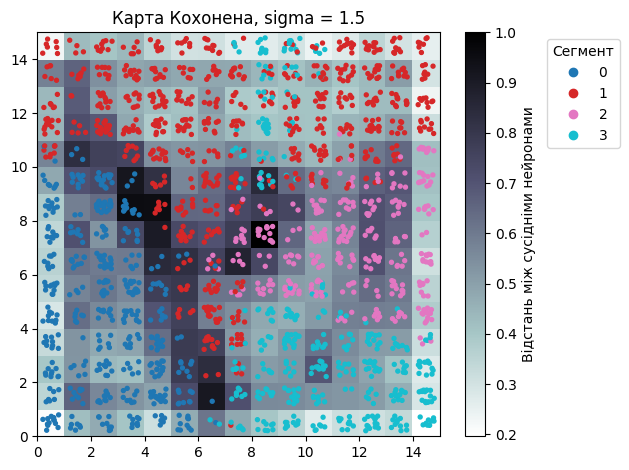

In [ ]:
def train_som(sigma):
    som = MiniSom(
        15,
        15,
        X.shape[1],
        sigma=sigma,
        learning_rate=0.5,
        random_seed=0
    )

    som.pca_weights_init(X)
    som.train(X, 20000, random_order=True)

    return som


# Навчаємо дві карти з різними радіусами
som = train_som(1.5)
som_small = train_som(0.5)

error_large = som.topographic_error(X)
error_small = som_small.topographic_error(X)

print( f"Топографічна помилка sigma = 1.5: {error_large:.3f}")

print( f"Топографічна помилка sigma = 0.5: {error_small:.3f}")

if error_large < error_small:
    print("Краще сусідство зберігає карта з sigma = 1.5.")
elif error_small < error_large:
    print("Краще сусідство зберігає карта з sigma = 0.5.")
else:
    print("Обидві карти мають однакову топографічну помилку.")

# Координати нейронів-переможців
winners = np.array([som.winner(x) for x in X]) + 0.5

# Невелике зміщення точок для наочності
jitter = np.random.default_rng(0).uniform(
    -0.3,
    0.3,
    size=winners.shape
)

# Відстані між сусідніми нейронами
mesh = plt.pcolor(
    som.distance_map().T,
    cmap="bone_r"
)

plt.colorbar(mesh, label="Відстань між сусідніми нейронами")

# Колір точки показує сегмент
points = plt.scatter(
    *(winners + jitter).T,
    c=labels,
    s=8,
    cmap="tab10"
)

plt.legend(
    *points.legend_elements(),
    title="Сегмент",
    loc="upper left",
    bbox_to_anchor=(1.25, 1)
)

plt.title("Карта Кохонена, sigma = 1.5")
plt.tight_layout()
plt.show()

## 9. Асоціативні правила

Правило «A → B» означає: у кого є A, у того часто є й B. Підтримка — частка абонентів, у яких є і A, і B. Достовірність — частка абонентів із B серед тих, у кого є A. Ліфт — у скільки разів достовірність більша за частку B у всій базі; ліфт 1 означає, що зв'язку немає.

Apriori відкидає набір, щойно його підтримка нижча за поріг, і вже не перевіряє ширших наборів із ним: ширший набір не може траплятися частіше за свою частину.

Код нижче вже будує таблицю «абонент × тип події» (подій `churn` у ній немає, замість них колонка `churned`) і знаходить правила з достовірністю від 0.3 для заданого порога підтримки.

1. Допишіть у `churn_rules` фільтр: лише правила, у яких наслідок рівно `churned` (`rules["consequents"] == frozenset({"churned"})`), відсортовані за ліфтом.
2. При підтримці 0.05 виведіть кількість цих правил і перші 5 із підтримкою, достовірністю й ліфтом.
3. При підтримці 0.10 виведіть, скільки правил лишилося.
4. Прочитайте найсильніше правило: у скільки разів частіше йдуть абоненти з цими подіями, ніж у середньому, і чому з вищим порогом правил менше, — це відповідь для питання 2 звіту.

In [ ]:
# Вилучаємо події churn, оскільки вони дублюють колонку churned
no_churn = events[events["event_type"] != "churn"]

# Створюємо таблицю "абонент × тип події"
basket = pd.crosstab(
    no_churn["abonent_id"],
    no_churn["event_type"]
) > 0

# Додаємо абонентів без подій
basket = basket.reindex(
    customers["abonent_id"],
    fill_value=False
)

# Додаємо цільову колонку
basket["churned"] = (
    customers["churned"].astype(bool).to_numpy()
)


def churn_rules(min_support):
    # Пошук частих наборів подій
    frequent = apriori(
        basket,
        min_support=min_support,
        use_colnames=True
    )

    # Побудова асоціативних правил
    rules = association_rules(
        frequent,
        num_itemsets=len(basket),
        metric="confidence",
        min_threshold=0.3
    )

    # Залишаємо правила, наслідок яких — тільки churned
    rules = rules[rules["consequents"] == frozenset({"churned"})]

    # Сортуємо за спаданням ліфту
    return rules.sort_values("lift",  ascending=False)


# Поріг підтримки 0.05
rules_005 = churn_rules(0.05)

print("Кількість правил при support = 0.05:", len(rules_005))

print("\nПерші 5 правил:")
print(
    rules_005[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(5).to_string(index=False)
)

# Поріг підтримки 0.10
rules_010 = churn_rules(0.10)

print("\nКількість правил при support = 0.10:", len(rules_010))

Кількість правил при support = 0.05: 25

Перші 5 правил:
                                   antecedents consequents  support  confidence     lift
           (contract_query, outage, complaint)   (churned)   0.0635    0.610577 2.866558
       (tariff_change, outage, contract_query)   (churned)   0.0525    0.596591 2.800896
(tariff_change, payment_delay, contract_query)   (churned)   0.0570    0.593750 2.787559
    (tariff_change, contract_query, complaint)   (churned)   0.0705    0.582645 2.735421
    (contract_query, payment_delay, complaint)   (churned)   0.0665    0.578261 2.714840

Кількість правил при support = 0.10: 10


## 10. Пастки (T-1, T-2, T-3)

Простий висновок із даних буває хибним. Що означає кожна пастка, сказано в таблиці в `README.md`. Перевірте кожну й виведіть числа, які порівнюються з порогом:

- **T-1:** кореляцію `voltage_dev_mean` і `loss_index_mean` по всій базі й окремо в кожному `district`;
- **T-2:** середню `seasonality` в абонентів із лічильниками `IND_1985`, у решти й відношення першої до другої;
- **T-3:** кореляцію `avg_price_uah_kwh` і `churned` серед 600 абонентів (30%) із найбільшим `annual_charge_uah` і серед решти.

Можуть допомогти `corr`, `groupby("district")` і `nlargest`.

In [ ]:
# Кореляція по всій базі
corr_all = customers["voltage_dev_mean"].corr( customers["loss_index_mean"])

print(f"Кореляція по всій базі: {corr_all:.4f}")

# Кореляції окремо в кожному районі
corr_district = customers.groupby("district").apply(
    lambda group: group["voltage_dev_mean"].corr(
        group["loss_index_mean"]
    )
)

print("\nКореляції за районами:")
print(corr_district.round(4))

# Перевірка умови пастки T-1
t1_exists = (abs(corr_all) > 0.2 and (corr_district.abs() < 0.1).all())

print("\nПастка T-1:", "Є" if t1_exists else "Немає")

# Середня сезонність IND_1985
seasonality_ind = customers.loc[
    customers["meter_type"] == "IND_1985",
    "seasonality"
].mean()

# Середня сезонність решти лічильників
seasonality_other = customers.loc[
    customers["meter_type"] != "IND_1985",
    "seasonality"
].mean()

# Відношення середніх
seasonality_ratio = seasonality_ind / seasonality_other

print(f"Сезонність IND_1985: {seasonality_ind:.4f}")
print(f"Сезонність решти: {seasonality_other:.4f}")
print(f"Відношення: {seasonality_ratio:.4f}")

# Перевірка умови пастки T-2
t2_exists = (seasonality_ratio < 0.8 or seasonality_ratio > 1.2)

print("\nПастка T-2:", "Є" if t2_exists else "Немає")

top_600 = customers.nlargest( 600, "annual_charge_uah")
remaining = customers.drop(index=top_600.index)

# Кореляції ціни й відходу
corr_top = top_600["avg_price_uah_kwh"].corr(top_600["churned"])

corr_remaining = remaining["avg_price_uah_kwh"].corr(remaining["churned"])

print( f"Кореляція серед 600 найбільших платників: {corr_top:.4f}")
print(f"Кореляція серед решти абонентів: {corr_remaining:.4f}")

# Пастка є, якщо кореляції мають протилежні знаки
t3_exists = (
    np.isfinite(corr_top)
    and np.isfinite(corr_remaining)
    and corr_top * corr_remaining < 0
)

print("\nПастка T-3:", "Є" if t3_exists else "Немає")


Кореляція по всій базі: -0.0013

Кореляції за районами:
district
centre   -0.0602
north     0.0693
south     0.0309
west     -0.0347
dtype: float64

Пастка T-1: Немає
Сезонність IND_1985: 0.9159
Сезонність решти: 1.5369
Відношення: 0.5960

Пастка T-2: Є
Кореляція серед 600 найбільших платників: 0.2072
Кореляція серед решти абонентів: 0.1849

Пастка T-3: Немає


## 11. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [17]:
x = np.asarray(X)
segments = pd.DataFrame({"abonent_id": customers["abonent_id"], "segment_id": labels})

assert x.shape == (2000, 5), "X має містити 2000 абонентів і 5 ознак із features"
assert np.allclose(x.mean(axis=0), 0) and np.allclose(x.std(axis=0), 1, atol=1e-3), "ознаки X не стандартизовано"
assert np.corrcoef(x[:, 0], np.log(customers["avg_daily_kwh"]))[0, 1] > 0.999, "перша колонка X — не логарифм avg_daily_kwh, або customers змінено чи пересортовано"
assert len(segments) == 2000 and segments["abonent_id"].is_unique, "має бути рядок на кожного з 2000 абонентів"
assert pd.api.types.is_integer_dtype(segments["segment_id"]), "segment_id мають бути цілі числа"
assert 3 <= segments["segment_id"].nunique() <= 6, "сегментів має бути від 3 до 6"

segments.to_csv("segments.csv", index=False)
print("усе гаразд:", segments["segment_id"].value_counts().sort_index().to_dict())

усе гаразд: {0: 476, 1: 778, 2: 322, 3: 424}
